# Image Category Distribution Plots
Using `data/Image categories (2).xlsx` — only IDs present in `data/combined_output/annotations.json`.

In [ ]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [5]:
import json
import openpyxl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import Counter

# ── Load annotation IDs ──────────────────────────────────────────────────────
with open('data/combined_output/annotations.json') as f:
    data = json.load(f)
ann_set = set(item['id'] for item in data)

# ── Load Excel ────────────────────────────────────────────────────────────────
def normalize_id(x):
    if isinstance(x, float) and x == int(x):
        return str(int(x))
    return str(x)

wb = openpyxl.load_workbook('data/Image categories (3).xlsx')
ws = wb.active

direct_cats = Counter()
inferential_cats = Counter()

for row in ws.iter_rows(values_only=True):
    if row[0] is None or row[0] == 'image id':
        continue
    img_id = normalize_id(row[0])
    if img_id not in ann_set:
        continue
    kind, subcat = row[1], row[2]
    if kind == 'direct':
        direct_cats[subcat] += 1
    elif kind == 'inferential':
        inferential_cats[subcat] += 1

print('Direct:',      dict(direct_cats),      '| total:', sum(direct_cats.values()))
print('Inferential:', dict(inferential_cats), '| total:', sum(inferential_cats.values()))

Direct: {'shadow': 47, 'mirror/glass': 76, 'water': 56, 'phone': 5, 'other reflection': 13} | total: 197
Inferential: {'machinery/technology': 45, 'culture': 27, 'nature': 24, 'sports/activity': 31, 'household': 44, 'symbol': 10} | total: 181


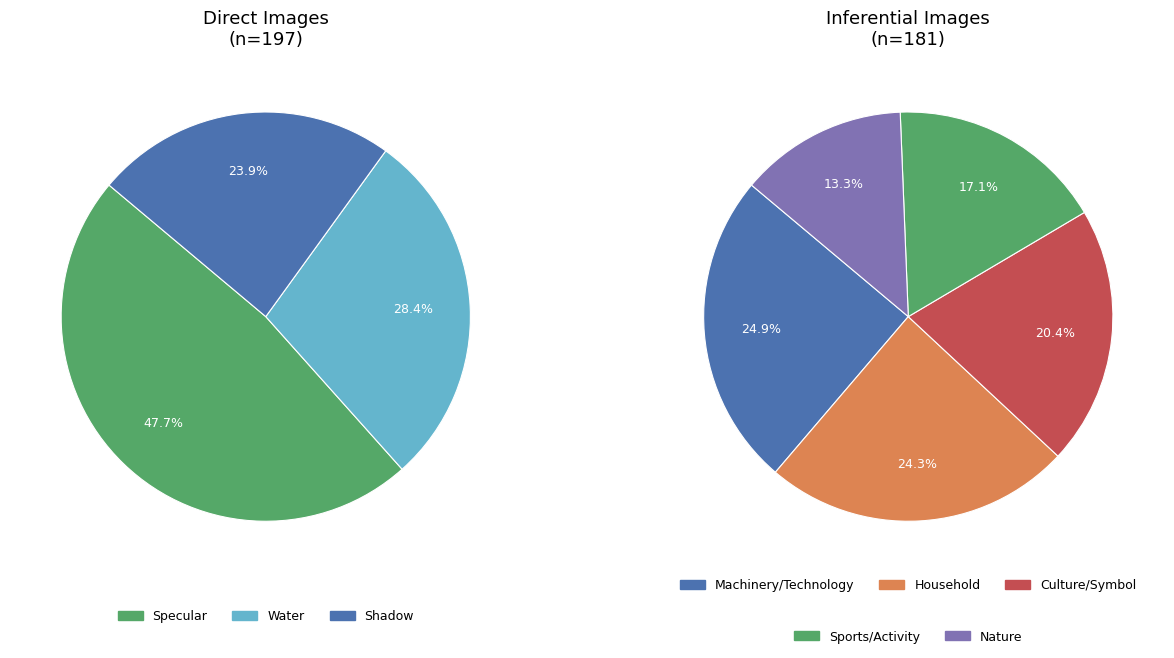

Saved.


In [6]:
direct_colors = {
    'shadow':        '#4C72B0',
    'specular':      '#55A868',
    'water':         '#64B5CD',
}

inferential_colors = {
    'household':            '#DD8452',
    'machinery/technology': '#4C72B0',
    'sports/activity':      '#55A868',
    'culture/symbol':       '#C44E52',
    'nature':               '#8172B3',
}

# Merge direct subcategories
direct_merged = Counter()
direct_merged['shadow']   = direct_cats.get('shadow', 0)
direct_merged['specular'] = direct_cats.get('mirror/glass', 0) + direct_cats.get('other reflection', 0) + direct_cats.get('phone', 0)
direct_merged['water']    = direct_cats.get('water', 0)

# Merge culture + symbol
inferential_merged = Counter(inferential_cats)
inferential_merged['culture/symbol'] = inferential_merged.pop('culture', 0) + inferential_merged.pop('symbol', 0)

def make_pie(ax, counter, color_map, title, legend_ncol=2, split_legend=False):
    labels_order = sorted(counter.keys(), key=lambda k: -counter[k])
    sizes  = [counter[k] for k in labels_order]
    colors = [color_map[k] for k in labels_order]
    total  = sum(sizes)

    wedges, texts, autotexts = ax.pie(
        sizes,
        labels=None,
        colors=colors,
        autopct=lambda pct: f'{pct:.1f}%' if pct >= 4 else '',
        pctdistance=0.72,
        startangle=140,
        wedgeprops=dict(linewidth=0.8, edgecolor='white'),
    )
    for at in autotexts:
        at.set_fontsize(9)
        at.set_color('white')

    patches = [mpatches.Patch(color=color_map[k], label=k.title())
               for k in labels_order]

    if split_legend:
        leg1 = ax.legend(handles=patches[:3], loc='lower center', bbox_to_anchor=(0.5, -0.06),
                         ncol=3, fontsize=9, frameon=False)
        ax.add_artist(leg1)
        ax.legend(handles=patches[3:], loc='lower center', bbox_to_anchor=(0.5, -0.16),
                  ncol=2, fontsize=9, frameon=False)
    else:
        ax.legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, -0.12),
                  ncol=legend_ncol, fontsize=9, frameon=False)

    ax.set_title(f'{title}\n(n={total})', fontsize=13, pad=12)


fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
fig.patch.set_facecolor('white')

make_pie(axes[0], direct_merged,      direct_colors,      'Direct Images',      legend_ncol=3)
make_pie(axes[1], inferential_merged, inferential_colors, 'Inferential Images', split_legend=True)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig('data/figures/image_category_distribution_pie.pdf', bbox_inches='tight', dpi=300)
plt.savefig('data/figures/image_category_distribution_pie.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved.')